In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

from scipy.spatial.transform import Rotation

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments

In [2]:
### INPUTS

het_vol_files = 'Data/het_models/'

n_vols = 8

scale = 2  # downsample scale

In [3]:
het_vols = []

vol_idx = np.linspace(0, 49, n_vols, endpoint=True).astype('int')

for k in vol_idx:
    with mrcfile.open(het_vol_files+'{}'.format(k)+'.mrc', permissive=True) as mrc:
        v = mrc.data
        dx = mrc.voxel_size.x
    
        v = transforms.block_average_downsample(v, scale)
        dx = dx * scale
            
        v = np.pad(v, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size (???)
        v = signals.Signal(v, d=3, dx=dx).preprocess_signals()[0]
        
        het_vols.append(v)
        mrc.close()

het_vols = np.array(het_vols)

f = het_vols[0].copy()

/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


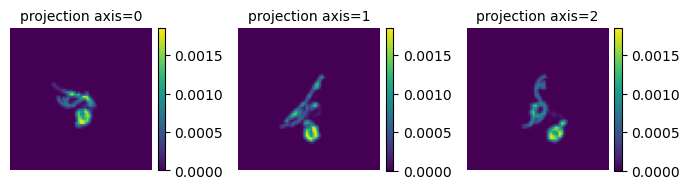

0.0 0.00035347196 0.12499999 0.9999999403953552


In [4]:
plots.orthogonal_2D_projection_plot(f)
print( np.amin(f), np.amax(f), np.sum(f), np.sum(f)*(dx**3) )

In [5]:
### Make the rotated volumes

het_vols_rotated = np.zeros(het_vols.shape)

for idx in range(n_vols):
    
    het_vols_rotated[idx] = het_vols[idx].copy()
    
    # het_vols_rotated[idx] = np.rot90(het_vols[idx].copy(), k=2)

    # rot_vol = transforms.rotate_voxel_zyz_fourier(het_vols[idx], 0.5*np.pi, 1.5*np.pi, 0.2*np.pi)
    # rot_vol = np.where(rot_vol<0, 0, rot_vol)
    # rot_vol = signals.Signal(rot_vol, d=3).preprocess_signals()[0]
    # het_vols_rotated[idx] = rot_vol

In [6]:
alignments_l2 = []
alignments_sw = []
alignments_rfsw = []

use_correlation = False  # if True, uses the correlation for the alignment instead of distance

for k in range(n_vols):
    print("=============")
    print("Volume: ", k)
    print("=============")

    g = het_vols_rotated[k]

    t = time.time()
    alignments_l2.append(alignments.Alignment(f, g, 'L2', use_correlation))
    print("alignment L2   = ", time.time() - t)
    print('\n')
    
    t = time.time()
    alignments_sw.append(alignments.Alignment(f, g, 'SW', use_correlation))
    print("alignment SW   = ", time.time() - t)
    print('\n')

    t = time.time()
    alignments_rfsw.append(alignments.Alignment(f, g, 'RFSW', use_correlation))
    print("alignment RFSW = ", time.time() - t)
    print('\n')

Volume:  0
correlation R=0:  6.177408876913211e-10
all correlation:  5.78735243134969e-10
alignment L2   =  5.34726095199585




/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3550: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  exec(code_obj, self.user_global_ns, self.user_ns)


correlation R=0:  3.3608364446780623
all correlation:  3.360687924950892
alignment SW   =  6.004034996032715




/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3550: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  exec(code_obj, self.user_global_ns, self.user_ns)


correlation R=0:  3.8567580213671535
all correlation:  3.846939468589462
correlation R=0:  3.858007422839836
all correlation:  3.850030973015979
alignment RFSW =  11.759108781814575


Volume:  1


/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3550: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  exec(code_obj, self.user_global_ns, self.user_ns)


correlation R=0:  4.065622680125698e-10
all correlation:  5.621443751819343e-10
alignment L2   =  5.2708680629730225


correlation R=0:  3.360926829233265
all correlation:  3.3627204712839855
alignment SW   =  6.0278990268707275


correlation R=0:  3.876254443832317
all correlation:  3.8904380796368434
correlation R=0:  3.86609807657044
all correlation:  3.880906443354861
alignment RFSW =  12.532854080200195


Volume:  2
correlation R=0:  2.9027287282280604e-10
all correlation:  4.71008476475637e-10
alignment L2   =  6.021414756774902


correlation R=0:  3.3567131556634355
all correlation:  3.3638459756413828
alignment SW   =  6.139438152313232


correlation R=0:  3.882712198213283
all correlation:  3.9066509959692817
correlation R=0:  3.8659585438641253
all correlation:  3.891712099226543
alignment RFSW =  11.885194063186646


Volume:  3
correlation R=0:  2.391561972591167e-10
all correlation:  4.113995044781108e-10
alignment L2   =  5.455595016479492


correlation R=0:  3.34846693706

In [7]:
distances_l2 = np.array([np.amin(alignments_l2[idx].distances) for idx in range(n_vols)])
distances_sw = np.array([np.amin(alignments_sw[idx].distances) for idx in range(n_vols)])
distances_rfsw = np.array([np.amin(alignments_rfsw[idx].distances) for idx in range(n_vols)])

dists_l2 = np.sqrt( distances_l2 / np.amax(distances_l2) )
dists_sw = np.sqrt( distances_sw / np.amax(distances_sw) )
dists_rfsw = np.sqrt( distances_rfsw / np.amax(distances_rfsw) )

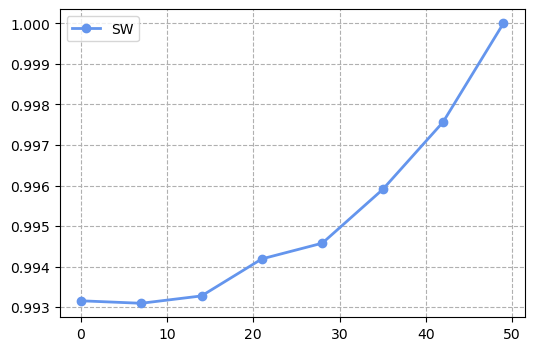

In [15]:
plt.figure(figsize=(6,4))

# plt.plot(vol_idx, dists_l2, color='salmon', marker='o', linewidth=2, label='L2')
plt.plot(vol_idx, dists_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx, dists_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

# plt.plot(vol_idx, distances_l2, color='salmon', marker='o', linewidth=2, label='L2')
# plt.plot(vol_idx, distances_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx, distances_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

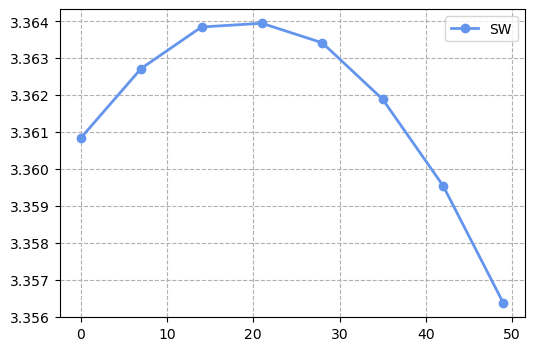

In [9]:
correlations_l2 = np.array([np.amax(alignments_l2[idx].correlations) for idx in range(n_vols)])
correlations_sw = np.array([np.amax(alignments_sw[idx].correlations) for idx in range(n_vols)])
correlations_rfsw = np.array([np.amax(alignments_rfsw[idx].correlations) for idx in range(n_vols)])

plt.figure(figsize=(6,4))

# plt.plot(vol_idx, correlations_l2, color='salmon', marker='o', linewidth=2, label='L2')
plt.plot(vol_idx, correlations_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx, correlations_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

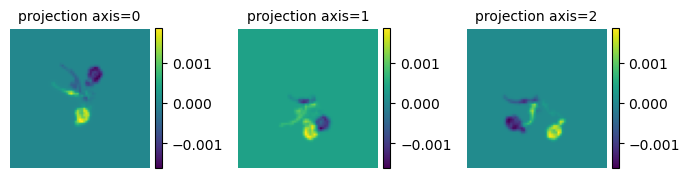

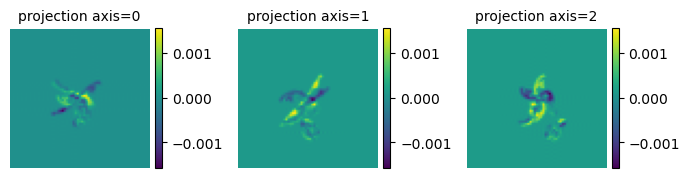

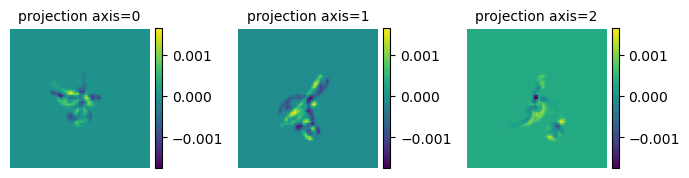

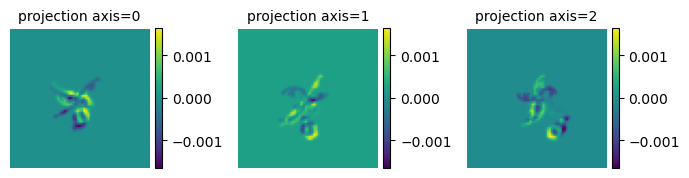

In [13]:
idx = -1
plots.orthogonal_2D_projection_plot(f - het_vols_rotated[idx])
plots.orthogonal_2D_projection_plot(f - alignments_l2[idx].aligned)
plots.orthogonal_2D_projection_plot(f - alignments_sw[idx].aligned)
plots.orthogonal_2D_projection_plot(f - alignments_rfsw[idx].aligned)

In [11]:
Rs_l2 = np.array([alignments_l2[idx].R for idx in range(n_vols)])
Rs_sw = np.array([alignments_sw[idx].R for idx in range(n_vols)])
Rs_rfsw = np.array([alignments_rfsw[idx].R for idx in range(n_vols)])

In [12]:
for idx in range(n_vols):
    print('Volume', idx)
    # print('  GT: ', np.rad2deg([omegas[k], betas[k], alphas[k]]))
    print('  L2: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(Rs_l2[idx].T)), 1 ))
    print('  SW: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(Rs_sw[idx].T)), 1 ))
    print('RFSW: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(Rs_rfsw[idx].T)), 1 ))
    print('\n')

Volume 0
  L2:  [  0.   0. 180.]
  SW:  [  0.   0. 180.]
RFSW:  [  0.   0. 180.]


Volume 1
  L2:  [ 76.2   2.8 -67.8]
  SW:  [ 73.4   2.8 -65.1]
RFSW:  [ 95.5   2.8 -87.2]


Volume 2
  L2:  [ 87.2   8.3 -67.8]
  SW:  [ 98.3  13.8 -78.9]
RFSW:  [23.5  2.8 -4.2]


Volume 3
  L2:  [-1.4  8.3 31.8]
  SW:  [ 92.8  19.4 -67.8]
RFSW:  [12.5  8.3 18. ]


Volume 4
  L2:  [20.8  8.3 20.8]
  SW:  [ 92.8  24.9 -56.8]
RFSW:  [15.2 13.8 26.3]


Volume 5
  L2:  [40.2 13.8  6.9]
  SW:  [ 95.5  41.5 -54. ]
RFSW:  [20.8 13.8 31.8]


Volume 6
  L2:  [56.8 19.4  1.4]
  SW:  [ 92.8  41.5 -40.2]
RFSW:  [20.8 19.4 42.9]


Volume 7
  L2:  [34.6 19.4 34.6]
  SW:  [ 92.8  52.6 -34.6]
RFSW:  [18.  24.9 62.3]


